In [2]:
import os
os.makedirs('data', exist_ok=True)
print('ready')

ready


Setup

In [3]:
import io, json, sys, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import yfinance as yf

START, END = '2021-01-01', '2025-01-01'     # END is exclusive
BENCH = '^GSPC'
USE_SNAPSHOT = False    # False = download now; True = only read saved files (use this on all later runs)

DATA_DIR = Path('data'); DATA_DIR.mkdir(exist_ok=True)
F_CONST  = DATA_DIR / 'sp500_constituents.csv'
F_HTML   = DATA_DIR / 'sp500_wikipedia_snapshot.html'
F_PRICES = DATA_DIR / 'raw_prices_long.csv.gz'
F_META   = DATA_DIR / 'metadata.json'

versions = {'python': sys.version.split()[0], 'pandas': pd.__version__,
            'numpy': np.__version__, 'yfinance': yf.__version__}
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66'}


Ticker list

In [4]:
WIKI_URL = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

if USE_SNAPSHOT:
    cons = pd.read_csv(F_CONST)
    meta = json.loads(F_META.read_text())
else:
    r = requests.get(WIKI_URL, headers={'User-Agent': 'Mozilla/5.0 (university coursework 6BUIS017W)'}, timeout=30)
    r.raise_for_status()
    F_HTML.write_text(r.text, encoding='utf-8')
    cons = pd.read_html(io.StringIO(r.text))[0]
    # Wikipedia writes BRK.B, Yahoo writes BRK-B
    cons['yf_ticker'] = cons['Symbol'].astype(str).str.strip().str.replace('.', '-', regex=False)
    cons.to_csv(F_CONST, index=False)
    now = datetime.now(timezone.utc)
    meta = {'wikipedia_url': WIKI_URL,
            'retrieval_date_utc': str(now.date()),
            'retrieval_timestamp_utc': now.isoformat(timespec='seconds'),
            'price_source': 'yfinance (auto_adjust=False)',
            'versions': versions, 'start': START, 'end_exclusive': END, 'benchmark': BENCH}
    F_META.write_text(json.dumps(meta, indent=2))

assert not cons['yf_ticker'].duplicated().any()
print(len(cons), 'tickers | retrieved:', meta['retrieval_date_utc'])
cons[['Symbol', 'yf_ticker', 'Security', 'GICS Sector']].head()

503 tickers | retrieved: 2026-11-14


,Symbol,yf_ticker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology


The price download

In [5]:
FIELDS = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

def download_batch(tick_list):
    d = yf.download(tick_list, start=START, end=END, auto_adjust=False, progress=False, threads=True)
    if d is None or d.empty:
        return None
    frames = []
    for f in FIELDS:
        w = d[f].copy(); w.index.name = 'Date'
        frames.append(w.melt(ignore_index=False, var_name='Ticker', value_name=f)
                       .reset_index().set_index(['Date', 'Ticker']))
    return pd.concat(frames, axis=1).reset_index()

if not USE_SNAPSHOT:
    tickers = cons['yf_ticker'].tolist() + [BENCH]
    parts = []
    for i in range(0, len(tickers), 50):
        got = download_batch(tickers[i:i + 50])
        if got is not None:
            parts.append(got)
        print(f'batch {i // 50 + 1}/{-(-len(tickers) // 50)} done')
    long_df = pd.concat(parts, ignore_index=True)

    missing = sorted(set(tickers) - set(long_df['Ticker'].unique()))
    if missing:
        print('retrying:', missing)
        retry = download_batch(missing if len(missing) > 1 else missing + [BENCH])
        if retry is not None:
            long_df = pd.concat([long_df, retry[retry['Ticker'].isin(missing)]], ignore_index=True)

    long_df.to_csv(F_PRICES, index=False, compression='gzip')
    meta['price_download_timestamp_utc'] = datetime.now(timezone.utc).isoformat(timespec='seconds')
    F_META.write_text(json.dumps(meta, indent=2))
    print('saved', F_PRICES, long_df.shape)

batch 1/11 done
batch 2/11 done
batch 3/11 done


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


batch 4/11 done


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


batch 5/11 done
batch 6/11 done
batch 7/11 done


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


batch 8/11 done


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


batch 9/11 done


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


batch 10/11 done
batch 11/11 done
saved data/raw_prices_long.csv.gz (506520, 8)


In [6]:
raw = pd.read_csv(F_PRICES, parse_dates=['Date'])
print('rows:', raw.shape[0], '| dates:', raw['Date'].min().date(), '->', raw['Date'].max().date())
print('tickers in file:', raw['Ticker'].nunique(), '| benchmark present:', BENCH in raw['Ticker'].values)
print('file size (MB):', round(F_PRICES.stat().st_size / 1e6, 1))

listed = set(cons['yf_ticker'])
got = set(raw['Ticker'])
failed = sorted(listed - got)
print('listed but NO data returned:', failed)
pd.DataFrame({'ticker': failed, 'reason': 'no data returned by yfinance'}).to_csv(DATA_DIR / 'failed_downloads.csv', index=False)

cov = raw.groupby('Ticker')['Date'].agg(first_date='min', last_date='max', n_obs='count')
cov.to_csv(DATA_DIR / 'download_coverage.csv')
print('shares with fewer rows than the benchmark:', int((cov['n_obs'] < cov.loc[BENCH, 'n_obs']).sum()))
cov.sort_values('n_obs').head()

rows: 506520 | dates: 2021-01-04 -> 2024-12-31
tickers in file: 504 | benchmark present: True
file size (MB): 13.1
listed but NO data returned: []
shares with fewer rows than the benchmark: 0


,first_date,last_date,n_obs
Ticker,,,
A,2021-01-04,2024-12-31,1005
AAPL,2021-01-04,2024-12-31,1005
ABBV,2021-01-04,2024-12-31,1005
ABNB,2021-01-04,2024-12-31,1005
ABT,2021-01-04,2024-12-31,1005


1.2: Validation and alignment

In [7]:
OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True)
RFM_BASE, RFM_WIN = 20, 60        # used later in 1.4; needed here to flag splits inside the RFM window

# --- duplicates ---
n_dup = int(raw.duplicated(['Date', 'Ticker']).sum())
print('duplicate (Date, Ticker) rows:', n_dup)
raw = raw.drop_duplicates(['Date', 'Ticker'], keep='first')

adj   = raw.pivot(index='Date', columns='Ticker', values='Adj Close').sort_index()
close = raw.pivot(index='Date', columns='Ticker', values='Close').sort_index()
vol   = raw.pivot(index='Date', columns='Ticker', values='Volume').sort_index()

# --- benchmark calendar = the reference set of trading dates ---
cal = adj[BENCH].dropna().index
print('benchmark trading days:', len(cal), '|', cal.min().date(), '->', cal.max().date())
assert cal.min() >= pd.Timestamp(START) and cal.max() < pd.Timestamp(END)
extra = adj.index.difference(cal)
print('dates present for shares but not in benchmark calendar:', len(extra))

# verify (don't assume) that the index has Adj Close = Close
print('^GSPC Adj Close equals Close on all dates:', np.allclose(adj.loc[cal, BENCH], close.loc[cal, BENCH]))

adj_c, close_c, vol_c = adj.reindex(cal), close.reindex(cal), vol.reindex(cal)

duplicate (Date, Ticker) rows: 0
benchmark trading days: 1005 | 2021-01-04 -> 2024-12-31
dates present for shares but not in benchmark calendar: 0
^GSPC Adj Close equals Close on all dates: True


Per-share checks and the exclusion log

In [8]:
cand = cons['yf_ticker'].tolist()
reasons = {}
def add(t, msg): reasons.setdefault(t, []).append(msg)

present = [t for t in cand if t in adj_c.columns]
stats = pd.DataFrame(index=cand)
stats['in_download']      = [t in adj_c.columns for t in cand]
stats['n_obs']            = adj_c[present].notna().sum().reindex(cand)
stats['n_missing_adj']    = adj_c[present].isna().sum().reindex(cand)
stats['n_missing_close']  = close_c[present].isna().sum().reindex(cand)
stats['n_missing_vol']    = vol_c[present].isna().sum().reindex(cand)
stats['n_nonpos_price']   = ((close_c[present] <= 0) | (adj_c[present] <= 0)).sum().reindex(cand)
stats['n_zero_or_neg_vol'] = (vol_c[present] <= 0).sum().reindex(cand)
stats['first_date']       = adj_c[present].apply(lambda s: s.first_valid_index()).reindex(cand)

for t in cand:
    s = stats.loc[t]
    if not s['in_download'] or s['n_obs'] == 0:
        add(t, 'no data returned by yfinance'); continue
    if s['n_obs'] < len(cal):
        add(t, f"unequal history: {int(s['n_obs'])}/{len(cal)} benchmark days (first date {pd.Timestamp(s['first_date']).date()})")
    if s['n_missing_close'] > 0 or s['n_missing_adj'] > 0:
        add(t, f"missing prices (Close {int(s['n_missing_close'])}, Adj {int(s['n_missing_adj'])})")
    if s['n_missing_vol'] > 0:
        add(t, f"missing volume on {int(s['n_missing_vol'])} days")
    if s['n_nonpos_price'] > 0:
        add(t, f"non-positive price on {int(s['n_nonpos_price'])} days")
    if s['n_zero_or_neg_vol'] > 0:
        add(t, f"zero/negative volume on {int(s['n_zero_or_neg_vol'])} days")

retained = [t for t in cand if t not in reasons]
info = cons.set_index('yf_ticker')
excl = pd.DataFrame([{'ticker': t, 'security': info.loc[t, 'Security'],
                      'sector': info.loc[t, 'GICS Sector'], 'reason': '; '.join(r)}
                     for t, r in reasons.items()],
                    columns=['ticker', 'security', 'sector', 'reason'])
print(f'Constituents: {len(cand)} | retained: {len(retained)} | excluded: {len(excl)}')
excl.to_csv(OUT_DIR / 'exclusion_log.csv', index=False)
stats.to_csv(OUT_DIR / 'validation_summary.csv')
excl

Constituents: 503 | retained: 486 | excluded: 17


,ticker,security,sector,reason
0,APP,AppLovin,Communication Services,unequal history: 935/1005 benchmark days (firs...
1,COIN,Coinbase,Financials,unequal history: 936/1005 benchmark days (firs...
2,CEG,Constellation Energy,Utilities,unequal history: 742/1005 benchmark days (firs...
3,EXE,Expand Energy,Energy,unequal history: 979/1005 benchmark days (firs...
4,FDXF,FedEx Freight,Industrials,no data returned by yfinance
5,FERG,Ferguson Enterprises,Industrials,zero/negative volume on 27 days
6,GEHC,GE HealthCare,Health Care,unequal history: 513/1005 benchmark days (firs...
7,GEV,GE Vernova,Industrials,unequal history: 193/1005 benchmark days (firs...
8,HONA,Honeywell Aerospace,Industrials,no data returned by yfinance
9,Q,Qnity Electronics,Information Technology,no data returned by yfinance


Corporate actions (splits and dividends)

In [9]:
# A split changes raw Close but not Adj Close, so implied is about the split ratio; normally it is about 1.
cr = close_c[retained].pct_change(fill_method=None)
ar = adj_c[retained].pct_change(fill_method=None)
implied = (1 + ar) / (1 + cr)
is_split = (implied > 1.4) | (implied < 0.7)
split_rows = [(t, d, float(implied.loc[d, t])) for t in retained for d in implied.index[is_split[t]]]
splits = pd.DataFrame(split_rows, columns=['ticker', 'date', 'implied_ratio'])

win_start = cal[-(RFM_BASE + RFM_WIN)]       # earliest session used by the RFM calculation
splits['in_rfm_window'] = splits['date'] >= win_start
print('split-like events in retained shares:', len(splits))
print('...inside the RFM window (last', RFM_BASE + RFM_WIN, 'sessions):', int(splits['in_rfm_window'].sum()))
splits.to_csv(OUT_DIR / 'split_events_detected.csv', index=False)

# how much dividend/split adjustment exists at the start (1.0 = none)
div_factor = (adj_c[retained] / close_c[retained]).iloc[0]
print(div_factor.describe().round(4))
splits.sort_values('date').tail(20)

split-like events in retained shares: 0
...inside the RFM window (last 80 sessions): 0
count    486.0000
mean       0.9027
std        0.0783
min        0.6460
25%        0.8463
50%        0.9087
75%        0.9732
max        1.0000
Name: 2021-01-04 00:00:00, dtype: float64


,ticker,date,implied_ratio,in_rfm_window


Survivorship bias: the S&P 500 list is today’s membership applied to 2021–2024. Companies removed since 2021 are missing and recent additions enter with strong histories, so average returns are biased upward

In [10]:
pd.DataFrame({'Close': close_c['NVDA'], 'Adj Close': adj_c['NVDA'], 'Volume': vol_c['NVDA']}).loc['2024-06-05':'2024-06-12']

,Close,Adj Close,Volume
Date,,,
2024-06-05,122.440002,122.091873,528402000.0
2024-06-06,120.998001,120.653969,664696000.0
2024-06-07,120.888000,120.544289,412386000.0
2024-06-10,121.790001,121.443718,313434100.0
2024-06-11,120.910004,120.576126,222551200.0
2024-06-12,125.199997,124.854271,299595000.0


1.3 Weekly return and weekly beta

Weekly prices and returns

In [11]:
# Panel of daily adjusted closes for retained shares + benchmark, on the benchmark calendar
panel = adj_c[retained].copy()
panel[BENCH] = adj_c[BENCH]
assert panel.notna().all().all(), 'unexpected missing values in retained panel'

# Friday-ending weeks, last available trading price in each week
wk = panel.resample('W-FRI').last()

# Drop incomplete first/last calendar weeks; keep holiday-shortened weeks
first_d, last_d = cal.min(), cal.max()
wk_end = wk.index
wk_start = wk_end - pd.Timedelta(days=4)                 # Monday of that week
complete = (wk_start >= first_d) & (wk_end <= last_d)
print('weeks dropped as incomplete:', [str(d.date()) for d in wk_end[~complete]])
wk = wk[complete]

# make sure there are no gaps: consecutive weeks only, so no multi-week change is ever called a 1-week return
assert (np.diff(wk.index.values).astype('timedelta64[D]').astype(int) == 7).all(), 'gap in weekly index'

# weekly return = this week's adj close / previous week's adj close - 1
rets = wk.pct_change().iloc[1:]
print('complete weeks:', len(wk), '| weekly return observations:', len(rets),
      '|', rets.index.min().date(), '->', rets.index.max().date())
print('NaNs in weekly returns:', int(rets.isna().sum().sum()))

weeks dropped as incomplete: ['2025-01-03']
complete weeks: 208 | weekly return observations: 207 | 2021-01-15 -> 2024-12-27
NaNs in weekly returns: 0


Mean weekly return, beta and checks

In [12]:
b = rets[BENCH]
mean_ret = rets[retained].mean()                          # arithmetic mean weekly return
beta = rets[retained].apply(lambda s: s.cov(b)) / b.var() # cov(share, benchmark) / var(benchmark)

# independent check: OLS slope computed a different way
chk = pd.Series({t: np.polyfit(b.values, rets[t].values, 1)[0] for t in retained})
print('max |beta - OLS slope|:', float((beta - chk).abs().max()))
assert (beta - chk).abs().max() < 1e-8

print('weekly observations per share:', len(rets))
print(pd.DataFrame({'mean_weekly_return': mean_ret, 'beta': beta}).describe().round(5))
print('\nlargest absolute weekly returns (sanity check for data errors):')
print(rets[retained].abs().stack().sort_values(ascending=False).head(5).round(3))

max |beta - OLS slope|: 1.9984014443252818e-15
weekly observations per share: 207
       mean_weekly_return       beta
count           486.00000  486.00000
mean              0.00286    0.97370
std               0.00265    0.40734
min              -0.00447    0.05545
25%               0.00118    0.66660
50%               0.00262    0.95061
75%               0.00421    1.17954
max               0.01777    3.77856

largest absolute weekly returns (sanity check for data errors):
Date        Ticker
2023-02-03  CVNA      0.860
2024-11-22  SMCI      0.784
2022-08-05  CVNA      0.612
2024-11-15  BE        0.605
2023-01-13  CVNA      0.592
dtype: float64


1.4 Adapted RFM

Recency, Frequency and Monetary

In [13]:
RFM_MULT = 2
obs_date = cal.max()                        # final common completed trading date
print('observation date:', obs_date.date())
assert obs_date < pd.Timestamp(END)

vol_r, close_r = vol_c[retained], close_c[retained]

# threshold for each share and day: 2 x mean volume of the PRECEDING 20 sessions (today excluded via shift(1))
base = vol_r.shift(1).rolling(RFM_BASE, min_periods=RFM_BASE).mean()
thr  = RFM_MULT * base
hv   = (vol_r > thr) & base.notna()         # strictly greater than twice the baseline

# 1.4.1 Recency: calendar days from latest high-volume day to the observation date
last_event = pd.Series({t: (hv.index[hv[t].values].max() if hv[t].any() else pd.NaT) for t in retained})
last_event = pd.to_datetime(last_event)
R = (obs_date - last_event).dt.days.astype('float')    # stays NaN if no event; never filled with 0

# 1.4.2 Frequency: number of high-volume days in the latest 60 sessions
F = hv.tail(RFM_WIN).sum()

# 1.4.3 Monetary: sum of Close x Volume over the latest 60 sessions (approx. traded value, USD)
M = (close_r * vol_r).tail(RFM_WIN).sum()

print('shares with no high-volume event (R missing):', int(R.isna().sum()))
print('shares with an event on the observation date (R = 0):', int((R == 0).sum()))
print('R range:', R.min(), '-', R.max(), '| F range:', int(F.min()), '-', int(F.max()))
print(f'M range: ${M.min():,.0f} - ${M.max():,.0f}')

observation date: 2024-12-31
shares with no high-volume event (R missing): 0
shares with an event on the observation date (R = 0): 0
R range: 4.0 - 222.0 | F range: 0 - 8
M range: $1,297,482,617 - $1,847,697,379,222


Edge-case checks

In [14]:
# 1) every day in the 60-session window has a valid 20-session baseline
assert base.tail(RFM_WIN).notna().all().all(), 'insufficient history for the baseline in the window'
# 2) every share has at least 20 + 60 sessions
n_sessions = vol_r.notna().sum()
assert (n_sessions >= RFM_BASE + RFM_WIN).all()
print('history check passed: min sessions =', int(n_sessions.min()), '(needed', RFM_BASE + RFM_WIN, ')')

# 3) threshold alignment: the baseline for the last day must be the mean of the 20 sessions BEFORE it
t0 = 'AAPL' if 'AAPL' in retained else retained[0]
i = len(cal) - 1
assert np.isclose(base[t0].iloc[i], vol_r[t0].iloc[i - RFM_BASE:i].mean())
print('threshold alignment check passed: current day is excluded from its own baseline')

history check passed: min sessions = 1005 (needed 80 )
threshold alignment check passed: current day is excluded from its own baseline


1.5: Interpretation and supporting evidence

Worked example and independent check

In [15]:
t = 'AAPL' if 'AAPL' in retained else retained[0]
ex = pd.DataFrame({'Close': close_r[t], 'Volume': vol_r[t], 'Prior20_mean_vol': base[t],
                   'Threshold_2x': thr[t], 'High_volume_day': hv[t]})
ex['Traded_value_USD'] = ex['Close'] * ex['Volume']
win = ex.tail(RFM_WIN)

print(f'WORKED EXAMPLE: {t}   observation date {obs_date.date()}')
print('Latest high-volume day :', last_event[t].date())
print('R = observation date - event date =', R[t], 'calendar days')
print('F = qualifying days in the last', RFM_WIN, 'sessions =', int(F[t]))
print(f'M = sum(Close x Volume) over the last {RFM_WIN} sessions = ${M[t]:,.0f}')
print('\nQualifying days inside the window:')
display(win[win['High_volume_day']].round(2))

# independent loop-based recomputation (different code path from the vectorised version)
rng = np.random.default_rng(0)
sample = list(rng.choice(retained, size=8, replace=False)) + [t]
for s in sample:
    v, c = vol_r[s].values, close_r[s].values
    flags = [(k >= RFM_BASE) and (v[k] > RFM_MULT * v[k - RFM_BASE:k].mean()) for k in range(len(v))]
    idx = [k for k, f in enumerate(flags) if f]
    r_loop = (obs_date - cal[idx[-1]]).days if idx else np.nan
    assert (np.isnan(r_loop) and np.isnan(R[s])) or r_loop == R[s], (s, 'R')
    assert sum(flags[-RFM_WIN:]) == F[s], (s, 'F')
    assert np.isclose(float(sum(c[-RFM_WIN:] * v[-RFM_WIN:])), M[s]), (s, 'M')
print('\nLoop-based recomputation matches the vectorised R, F and M for', len(sample), 'shares')

WORKED EXAMPLE: AAPL   observation date 2024-12-31
Latest high-volume day : 2024-12-20
R = observation date - event date = 11.0 calendar days
F = qualifying days in the last 60 sessions = 2
M = sum(Close x Volume) over the last 60 sessions = $623,303,377,707

Qualifying days inside the window:


,Close,Volume,Prior20_mean_vol,Threshold_2x,High_volume_day,Traded_value_USD
Date,,,,,,
2024-11-25,232.87,90152800.0,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.49,147495300.0,45004605.0,90009210.0,True,3.753608e+10



Loop-based recomputation matches the vectorised R, F and M for 9 shares


Feature table (one row per included share)

In [16]:
feat = pd.DataFrame({'ticker': retained})
feat['security'] = feat['ticker'].map(info['Security'])
feat['sector']   = feat['ticker'].map(info['GICS Sector'])
feat['n_weekly_obs']       = len(rets)
feat['mean_weekly_return'] = feat['ticker'].map(mean_ret)
feat['beta']               = feat['ticker'].map(beta)
feat['last_hv_date']       = feat['ticker'].map(last_event)
feat['R_days']             = feat['ticker'].map(R)
feat['F_count']            = feat['ticker'].map(F)
feat['M_usd']              = feat['ticker'].map(M)
feat['rfm_valid']          = feat['R_days'].notna()
feat['common_valid_set']   = feat['rfm_valid'] & feat[['mean_weekly_return', 'beta']].notna().all(axis=1)

feat.to_csv(OUT_DIR / 'task1_feature_table.csv', index=False)
rets[retained + [BENCH]].to_csv(OUT_DIR / 'weekly_returns.csv')
print('feature table rows:', len(feat), '| common valid share set for clustering:', int(feat['common_valid_set'].sum()))
feat.head()

feature table rows: 486 | common valid share set for clustering: 486


,ticker,security,sector,n_weekly_obs,mean_weekly_return,beta,last_hv_date,R_days,F_count,M_usd,rfm_valid,common_valid_set
0,MMM,3M,Industrials,207,0.001142,0.869079,2024-12-20,11.0,4,2.599146e+10,True,True
1,AOS,A. O. Smith,Industrials,207,0.001991,1.042805,2024-12-20,11.0,2,4.748980e+09,True,True
2,ABT,Abbott Laboratories,Health Care,207,0.000971,0.583543,2024-12-20,11.0,1,3.523027e+10,True,True
3,ABBV,AbbVie,Health Care,207,0.003749,0.425365,2024-12-20,11.0,3,6.837054e+10,True,True
4,ACN,Accenture,Information Technology,207,0.002376,1.143300,2024-12-20,11.0,2,5.199430e+10,True,True


Summaries, histograms and run record

                    count          mean           std           min  \
mean_weekly_return  486.0  2.900000e-03  2.700000e-03 -4.500000e-03   
beta                486.0  9.737000e-01  4.073000e-01  5.550000e-02   
R_days              486.0  2.040740e+01  2.134240e+01  4.000000e+00   
F_count             486.0  2.989700e+00  1.330800e+00  0.000000e+00   
M_usd               486.0  3.940419e+10  1.291388e+11  1.297483e+09   

                             25%           50%           75%           max  
mean_weekly_return  1.200000e-03  2.600000e-03  4.200000e-03  1.780000e-02  
beta                6.666000e-01  9.506000e-01  1.179500e+00  3.778600e+00  
R_days              1.100000e+01  1.100000e+01  1.475000e+01  2.220000e+02  
F_count             2.000000e+00  3.000000e+00  4.000000e+00  8.000000e+00  
M_usd               1.019517e+10  1.668382e+10  3.227689e+10  1.847697e+12  

skewness:
mean_weekly_return     0.87
beta                   1.10
R_days                 3.65
F_count         

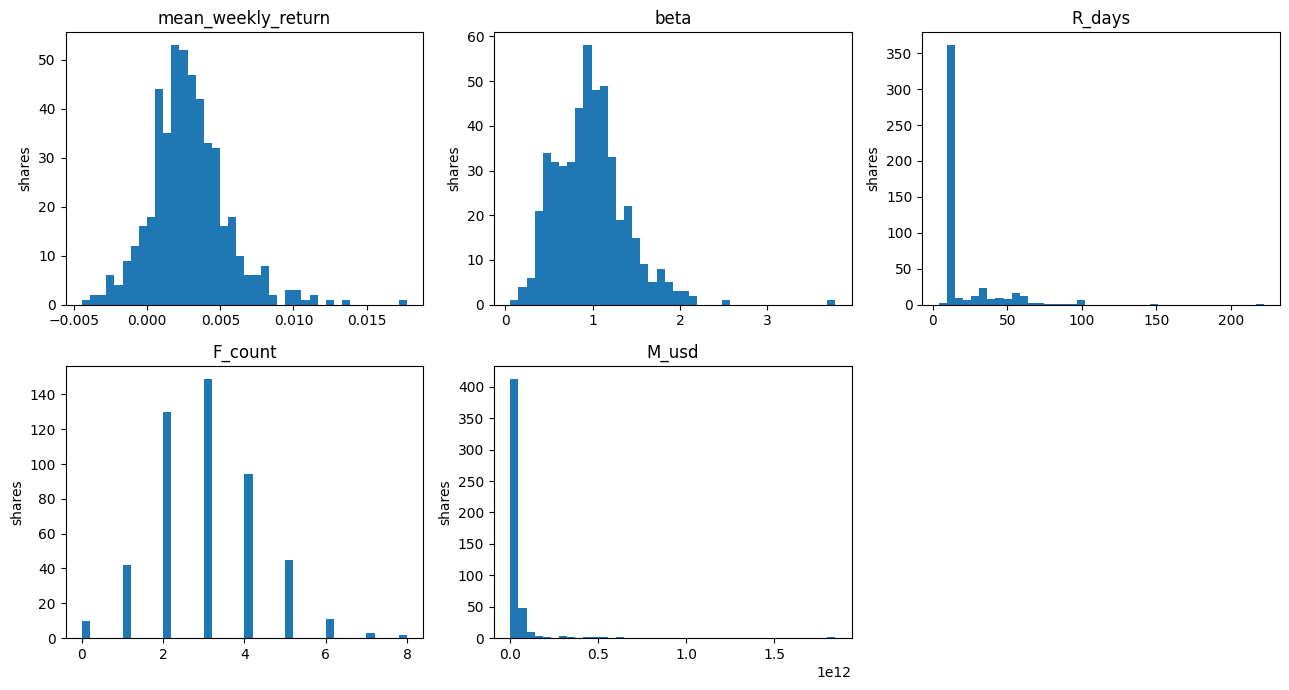

715

In [17]:
cols = ['mean_weekly_return', 'beta', 'R_days', 'F_count', 'M_usd']
print(feat[cols].describe().round(4).T)
print('\nskewness:'); print(feat[cols].skew().round(2))
print('\nshares per sector:'); print(feat['sector'].value_counts())

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), cols):
    ax.hist(feat[c].dropna(), bins=40); ax.set_title(c); ax.set_ylabel('shares')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR / 'task1_feature_distributions.png', dpi=150); plt.show()

meta.update({'observation_date': str(obs_date.date()), 'n_constituents_listed': len(cand),
             'n_retained': len(retained), 'n_excluded': int(len(excl)), 'n_weekly_returns': int(len(rets)),
             'rfm': {'baseline_sessions': RFM_BASE, 'window_sessions': RFM_WIN, 'multiple': RFM_MULT}})
(OUT_DIR / 'run_metadata.json').write_text(json.dumps(meta, indent=2, default=str))